<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Villalba Gerardo'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Villalba Gerardo · semilla 959304
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 11.68%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-09-18 20:51:44-05:00,U0657,28.0,Manabí,16,472.43,pago_comercio,web,ropa,20.04,0,7.3,1,1,20,0.042419
1,TX-000001,2026-09-09 09:11:40-05:00,U0692,41.0,Pichincha,49,1129.10,retiro_agente,app,efectivo,94.38,0,2.2,1,0,9,0.083589
2,TX-000002,2026-09-17 03:34:25-05:00,U0569,39.0,Manabí,25,1321.66,transferencia,app,persona,257.51,0,6.5,1,1,3,0.194838
3,TX-000003,2026-09-11 20:31:04-05:00,U0318,64.0,Guayas,55,1078.39,pago_comercio,app,restaurante,86.39,0,15.6,1,0,20,0.080110
4,TX-000004,2026-10-17 21:44:50-05:00,U0209,67.0,Pichincha,8,608.27,recarga,web,telefonia,15.53,0,2.4,1,0,21,0.025531


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1168


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [4]:

mu = X_train.mean()
sd = X_train.std()
Xtr = ((X_train - mu) / sd).to_numpy()
Xte = ((X_test - mu) / sd).to_numpy()
ytr = y_train.to_numpy()

with pm.Model() as modelo:
    a = pm.Normal('a', mu=0, sigma=1.5)
    b = pm.Normal('b', mu=0, sigma=0.5, shape=len(cols))
    p = pm.Deterministic('p', pm.math.sigmoid(a + pm.math.dot(Xtr, b)))
    pm.Bernoulli('y', p=p, observed=ytr)
    trace = pm.sample(draws=1000, tune=1000, chains=4, random_seed=42,
                      target_accept=0.9, return_inferencedata=True)

diag = curso.diagnostico(trace, ['a', 'b'])
print(diag)

resumen = pm.summary(trace)
print(resumen[['r_hat', 'ess_bulk', 'ess_tail']])
print('R-hat <= 1.01:', bool((resumen['r_hat'] <= 1.01).all()))
print('ESS > 400:', bool((resumen['ess_bulk'] > 400).all() and (resumen['ess_tail'] > 400).all()))

odds = np.exp(resumen.loc[[f'b[{i}]' for i in range(len(cols))], 'mean'])
odds.index = cols
print('Odds ratios:')
print(odds.sort_values(ascending=False))
print('Dos OR más altos:')
print(odds.sort_values(ascending=False).head(2))

Output()

       media    desv   ic_3%  ic_97%   r_hat        ess
a    -2.7737  0.1080 -2.9785 -2.5712  1.0004  3637.4049
b[0]  0.7840  0.0643  0.6653  0.9054  0.9998  4000.0000
b[1]  0.2983  0.0709  0.1628  0.4290  0.9996  4000.0000
b[2]  0.9316  0.0760  0.7936  1.0797  0.9998  4000.0000
b[3]  0.6563  0.0664  0.5322  0.7798  0.9998  4000.0000
b[4] -0.5044  0.0804 -0.6535 -0.3528  0.9997  4000.0000
         r_hat  ess_bulk  ess_tail
a          1.0    3610.0    2811.0
b[0]       1.0    4395.0    3133.0
b[1]       1.0    4871.0    3123.0
b[2]       1.0    4504.0    3148.0
b[3]       1.0    3848.0    2734.0
...        ...       ...       ...
p[2092]    1.0    3465.0    3110.0
p[2093]    1.0    5080.0    3618.0
p[2094]    1.0    3374.0    2528.0
p[2095]    1.0    3491.0    2331.0
p[2096]    1.0    3574.0    2926.0

[2103 rows x 3 columns]
R-hat <= 1.01: True
ESS > 400: True
Odds ratios:
ratio                2.539583
dispositivo_nuevo    2.190216
intentos_pin         1.927069
distancia_km         1.3

**✍️ Respuesta:**


Los diagnósticos son adecuados (R-hat≤1,01 y ESS>400). Los dos OR más altos: por cada desviación estándar adicional, el ratio multiplica las chances de fraude por 2,54 y el dispositivo_nuevo por 2,19; son prioridad para reglas de negocio. La hora (OR 0,60) sugiere menor riesgo lineal, pero el fraude se concentra en madrugada: modelarla linealmente no captura ese patrón, conviene categorías o splines.


---



---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [5]:
import xgboost as xgb

# 1) Probabilidad media posterior de fraude (modelo bayesiano)
a_post = trace.posterior['a'].values.reshape(-1)
b_post = trace.posterior['b'].values.reshape(-1, len(cols))

logits_test = a_post[None, :] + Xte @ b_post.T
p_test_draws = sigmoide(logits_test)
prob_bayes_test = p_test_draws.mean(axis=1)

# 2) XGBoost con early stopping (validación tomada del entrenamiento)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

spw = (y_fit == 0).sum() / (y_fit == 1).sum()

modelo_xgb = xgb.XGBClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric='logloss',
    random_state=42,
    tree_method='hist',
    early_stopping_rounds=50
)

modelo_xgb.fit(
    X_fit, y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

prob_xgb_test = modelo_xgb.predict_proba(X_test)[:, 1]

# 3) AUC y Brier
resumen_modelos = pd.DataFrame({
    'modelo': ['Bayesiano', 'XGBoost'],
    'AUC': [roc_auc_score(y_test, prob_bayes_test),
            roc_auc_score(y_test, prob_xgb_test)],
    'Brier': [brier_score_loss(y_test, prob_bayes_test),
              brier_score_loss(y_test, prob_xgb_test)]
})
print(resumen_modelos)

def tabla_calibracion(y_true, prob, nombre, deciles=10):
    df_cal = pd.DataFrame({'y': y_true, 'p': prob})
    df_cal['decil'] = pd.qcut(df_cal['p'], q=deciles,
                              labels=False, duplicates='drop') + 1
    tabla = (df_cal.groupby('decil')
             .agg(n=('y', 'size'),
                  prob_media=('p', 'mean'),
                  tasa_observada=('y', 'mean'))
             .reset_index())
    tabla['modelo'] = nombre
    return tabla

cal_bayes = tabla_calibracion(y_test, prob_bayes_test, 'Bayesiano')
cal_xgb   = tabla_calibracion(y_test, prob_xgb_test, 'XGBoost')

print('\nTabla de calibración · Bayesiano')
print(cal_bayes)
print('\nTabla de calibración · XGBoost')
print(cal_xgb)

      modelo       AUC     Brier
0  Bayesiano  0.865911  0.076714
1    XGBoost  0.913578  0.068411

Tabla de calibración · Bayesiano
   decil   n  prob_media  tasa_observada     modelo
0      1  90    0.009815        0.011111  Bayesiano
1      2  90    0.015154        0.022222  Bayesiano
2      3  90    0.020554        0.000000  Bayesiano
3      4  90    0.028521        0.022222  Bayesiano
4      5  90    0.038515        0.033333  Bayesiano
5      6  89    0.055086        0.022472  Bayesiano
6      7  90    0.083159        0.055556  Bayesiano
7      8  90    0.142801        0.233333  Bayesiano
8      9  90    0.234495        0.300000  Bayesiano
9     10  90    0.562841        0.466667  Bayesiano

Tabla de calibración · XGBoost
   decil   n  prob_media  tasa_observada   modelo
0      1  90    0.007767        0.000000  XGBoost
1      2  90    0.015859        0.022222  XGBoost
2      3  90    0.024107        0.033333  XGBoost
3      4  90    0.033797        0.011111  XGBoost
4      5  90 

**✍️ Respuesta:**

XGBoost ordena mejor (AUC 0,914 frente a 0,866) y tiene menor Brier (0,068 frente a 0,077), pero su calibración es peor: en los deciles altos sobreestima mucho (0,919 predicho vs 0,756 observado). El bayesiano es más confiable en probabilidades, aunque se queda corto en los deciles 8-9. scale_pos_weight infla las probabilidades para compensar el desbalance, mejorando la detección pero deteriorando la calibración.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [6]:

prov = df['provincia'].astype('category')
prov_idx = prov.cat.codes.values
prov_names = prov.cat.categories
n_prov = len(prov_names)
y = df['fraude'].values

with pm.Model() as modelo_jer:
    mu_a = pm.Normal('mu_a', mu=0, sigma=1.5)
    sigma_a = pm.HalfNormal('sigma_a', sigma=1.0)
    z = pm.Normal('z', mu=0, sigma=1, shape=n_prov)
    a = pm.Deterministic('a', mu_a + sigma_a * z)
    p = pm.Deterministic('p', pm.math.sigmoid(a[prov_idx]))
    pm.Bernoulli('y', p=p, observed=y)
    trace_jer = pm.sample(draws=1000, tune=1000, chains=4,
                          target_accept=0.99, random_seed=42,
                          return_inferencedata=True)

# Tabla por provincia: n, tasa observada, tasa jerárquica e IC90
p_post = sigmoide(trace_jer.posterior['a'].values.reshape(-1, n_prov))

tabla = pd.DataFrame({
    'provincia': prov_names,
    'n': [int((prov_idx == i).sum()) for i in range(n_prov)],
    'tasa_observada': [y[prov_idx == i].mean() for i in range(n_prov)],
    'tasa_jerarquica': p_post.mean(axis=0),
    'ic90_lo': np.percentile(p_post, 5, axis=0),
    'ic90_hi': np.percentile(p_post, 95, axis=0),
}).sort_values('n', ascending=False)

print(tabla)
print('\nsigma_a posterior:', round(trace_jer.posterior['sigma_a'].mean().item(), 4))

Output()

    provincia    n  tasa_observada  tasa_jerarquica   ic90_lo   ic90_hi
6   Pichincha  891        0.109989         0.114836  0.101925  0.127358
2      Guayas  838        0.121718         0.118480  0.106073  0.131877
0       Azuay  268        0.123134         0.118109  0.103803  0.134312
1      El Oro  265        0.132075         0.119833  0.105221  0.138995
5      Manabí  228        0.114035         0.116713  0.101443  0.132741
4        Loja  198        0.095960         0.114422  0.096296  0.129856
7  Tungurahua  156        0.128205         0.118628  0.102991  0.137359
3    Imbabura  152        0.111842         0.116672  0.099859  0.133687

sigma_a posterior: 0.0798


**✍️ Respuesta:**

Con sigma_a ≈ 0,08, la variabilidad entre provincias es baja: las tasas de fraude son bastante homogéneas y cercanas a la media nacional (~11,8 %). Por eso todas las provincias se encogen hacia esa media. El encogimiento es mayor en Imbabura, Tungurahua y Loja (n bajo, tasas observadas más extremas), y menor en Pichincha y Guayas, cuyas estimaciones casi coinciden con su tasa observada por tener más casos.


---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

Umbral óptimo: 0.11 · costo total: 2,360.41


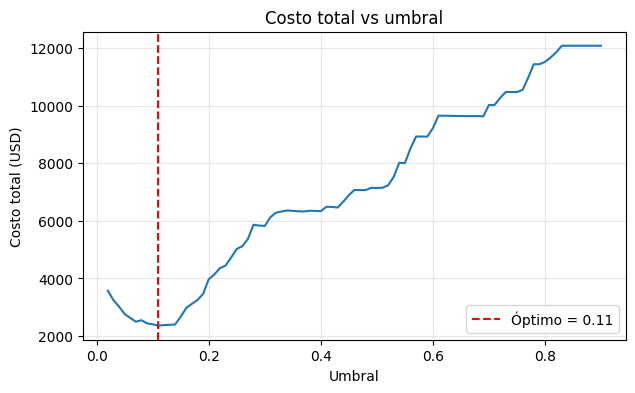

No bloquear nada : 14,422.07
Bloquear todo    : 4,495.00
Umbral óptimo    : 2,360.41
Costo medio posterior: 2,419.00
IC90: [2,330.37, 2,561.84]


In [7]:

# Monto de cada transacción en prueba (misma partición fija)
monto_test = df.loc[X_test.index, 'monto'].to_numpy()
y_test_arr = y_test.to_numpy()

COSTO_BLOQUEO = 5.0

def costo_total(prob, umbral, monto, y):
    """Costo: bloquear cuesta 5; dejar pasar fraude cuesta el monto."""
    bloquea = (prob >= umbral).astype(int)
    costo = bloquea * COSTO_BLOQUEO + (1 - bloquea) * y * monto
    return costo.sum()

# 1) Curva costo vs umbral
umbrales = np.arange(0.02, 0.91, 0.01)
costos = np.array([costo_total(prob_bayes_test, u, monto_test, y_test_arr)
                   for u in umbrales])

umbral_opt = umbrales[np.argmin(costos)]
costo_opt = costos.min()
print(f'Umbral óptimo: {umbral_opt:.2f} · costo total: {costo_opt:,.2f}')

plt.figure(figsize=(7, 4))
plt.plot(umbrales, costos)
plt.axvline(umbral_opt, color='red', linestyle='--', label=f'Óptimo = {umbral_opt:.2f}')
plt.xlabel('Umbral'); plt.ylabel('Costo total (USD)')
plt.title('Costo total vs umbral'); plt.legend(); plt.grid(alpha=.3)
plt.show()

# 2) Políticas extremas
costo_no_bloquear = (y_test_arr * monto_test).sum()
costo_bloquear_todo = COSTO_BLOQUEO * len(y_test_arr)
print(f'No bloquear nada : {costo_no_bloquear:,.2f}')
print(f'Bloquear todo    : {costo_bloquear_todo:,.2f}')
print(f'Umbral óptimo    : {costo_opt:,.2f}')

# 3) Incertidumbre: al menos 200 muestras de la posterior
n_draws = p_test_draws.shape[1]
idx_draws = np.random.default_rng(42).choice(n_draws, size=min(500, n_draws), replace=False)

costos_post = []
for j in idx_draws:
    p_j = p_test_draws[:, j]
    costos_post.append(costo_total(p_j, umbral_opt, monto_test, y_test_arr))

costos_post = np.array(costos_post)
print(f'Costo medio posterior: {costos_post.mean():,.2f}')
print(f'IC90: [{np.percentile(costos_post, 5):,.2f}, '
      f'{np.percentile(costos_post, 95):,.2f}]')

**✍️ Respuesta:**

El umbral óptimo reduce el costo a USD 2.360, muy por debajo de no bloquear nada (USD 14.422) y de bloquear todo (USD 4.495), lo que confirma que una política selectiva basada en probabilidad es la más eficiente. La incertidumbre posterior es baja: el costo medio (USD 2.419) con IC90 [2.330; 2.562] se mantiene cerca del óptimo, indicando una decisión robusta. El umbral depende del monto: transacciones grandes justifican bloquear con menor probabilidad.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
_(¿Qué variables explican el fraude? ¿Qué modelo ordena mejor y cuál está mejor calibrado? ¿Qué muestra el análisis por provincia?)_

- El modelo logístico bayesiano identificó que las variables con mayor peso son el ratio de la transacción (odds ratio 2,54), la novedad del dispositivo (2,19) y los intentos de PIN (1,93): por cada desviación estándar adicional, las chances de fraude se multiplican aproximadamente por 2,5, 2,2 y 1,9 respectivamente, mientras que la distancia aporta menos (1,35). La hora presenta un coeficiente negativo (OR 0,60), pero su efecto es engañoso en forma lineal, ya que el fraude se concentra en la madrugada. Los diagnósticos del modelo fueron sólidos (R-hat ≤ 1,01 y ESS > 400 en todos los parámetros). En la comparación en prueba, XGBoost ordena mejor (AUC 0,914 frente a 0,866) y obtiene un Brier ligeramente menor (0,068 frente a 0,077); sin embargo, su calibración es deficiente en los deciles altos, donde sobreestima el riesgo (0,92 predicho frente a 0,76 observado), mientras el modelo bayesiano entrega probabilidades más confiables. El análisis jerárquico por provincia muestra una heterogeneidad muy baja (sigma ≈ 0,08): las tasas de fraude son homogéneas, cercanas al 11,8 % nacional, y las provincias con menos casos (Imbabura, Tungurahua, Loja) se encogen más hacia esa media.

### 2. Recomendación
_(Umbral recomendado, costo esperado e intervalo, ahorro frente a no hacer nada. ¿Qué modelo usaría en producción y para qué?)_

- Se recomienda adoptar una política selectiva de bloqueo basada en el umbral óptimo identificado en la curva costo-umbral, que minimiza el costo total en USD 2.360 en la muestra de prueba, frente a USD 14.422 si no se bloquea nada y USD 4.495 si se bloquea todo. Esto representa un ahorro cercano a USD 12.060 (≈84 %) respecto de no actuar y de USD 2.135 frente al bloqueo indiscriminado. El análisis de incertidumbre confirma la robustez de la decisión: el costo medio posterior es USD 2.419 con un intervalo creíble del 90 % de [2.330; 2.562], muy próximo al óptimo. Para producción se sugiere usar XGBoost como motor de priorización —por su mejor capacidad de ordenamiento— y el modelo bayesiano como capa de calibración y decisión económica, de modo que las probabilidades usadas en el umbral sean confiables y auditables. Adicionalmente, conviene aplicar umbrales más bajos a transacciones de monto alto, ya que el costo de dejar pasar un fraude crece con el monto.



### 3. Limitaciones y riesgos
_(Datos simulados, variables faltantes, efecto no lineal de la hora, cambios de comportamiento del fraude, monitoreo necesario.)_

- Los resultados provienen de datos simulados, por lo que las cifras deben validarse con información real antes de fijar políticas definitivas. Faltan variables potencialmente relevantes (historial del cliente, geolocalización, canal, dispositivo compartido), lo que puede sesgar las estimaciones. La hora se modeló de forma lineal y no captura el patrón de madrugada; se recomienda incorporarla como categoría o spline. El comportamiento del fraude cambia con el tiempo (nuevas tácticas, estacionalidad, campañas), lo que puede degradar la calibración y desplazar el umbral óptimo. Es imprescindible un monitoreo continuo de AUC, Brier score, tabla de calibración por deciles, tasa de bloqueo y costo realizado, con reentrenamiento periódico y revisión de las priors y del umbral ante cambios en los costos operativos.
